In [156]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("raw/dataset0304")

# Загрузка данных
issues = pd.read_csv(DATA_DIR / "issues.csv")
epics = pd.read_csv(DATA_DIR / "epics.csv")
sprints = pd.read_csv(DATA_DIR / "sprints.csv")
projects = pd.read_csv(DATA_DIR / "projects.csv")

# Преобразование дат
issues["created_at"] = pd.to_datetime(issues["created_at"])
issues["resolved_at"] = pd.to_datetime(issues["resolved_at"])

sprints["start_date"] = pd.to_datetime(sprints["start_date"])
sprints["end_date"] = pd.to_datetime(sprints["end_date"])

# 1. Отбор завершённых задач
df = issues[issues["resolved_at"].notna()].copy()

# 2. Добавление названий проектов
df = df.merge(
    projects[["project_id", "project_name"]],
    on="project_id",
    how="left",
    validate="many_to_one"
)

# 3. Присоединение спринтов
df = df.merge(
    sprints[
        ["sprint_id", "project_id", "sprint_name",
         "start_date", "end_date"]
    ],
    on=["sprint_id", "project_id"],
    how="left",
    validate="many_to_one"
)

# 4. Присоединение эпиков
df = df.merge(
    epics[["epic_id", "project_id", "epic_name"]],
    on=["epic_id", "project_id"],
    how="left",
    validate="many_to_one"
)

# 5. Извлечение специализации из названия эпика
df["specialization"] = df["epic_name"].str.extract(
    r"\(([^()]+)\)\s*$"
)

print("Исходных задач:", len(issues))
print("Отобранных задач:", len(df))

display(df.head())


Исходных задач: 500
Отобранных задач: 415


,issue_id,issue_key,project_id,team_id,epic_id,assignee_id,issue_type,priority,summary,created_at,resolved_at,story_points,current_status,sprint_id,project_name,sprint_name,start_date,end_date,epic_name,specialization
0,1,PROJA-00001,1,1,1,2,Story,P3,Build offline sync page,2025-08-02 11:23:00,2025-08-19 13:23:00,3,Done,42,Project A,PROJA Sprint 042,2025-07-28,2025-08-10,Checkout experience (PHP),PHP
1,2,PROJA-00002,1,1,1,2,Story,P3,Build payments page,2024-10-17 16:09:00,2024-11-04 17:09:00,5,Done,21,Project A,PROJA Sprint 021,2024-10-07,2024-10-20,Checkout experience (PHP),PHP
2,3,PROJA-00003,1,1,1,2,Bug,P2,Resolve UI regression in payments,2024-08-12 13:36:00,2024-08-17 17:36:00,2,Done,17,Project A,PROJA Sprint 017,2024-08-12,2024-08-25,Checkout experience (PHP),PHP
3,4,PROJA-00004,1,1,1,1,Story,P1,Create settings admin tool,2025-01-28 11:46:00,2025-02-06 15:46:00,5,Done,29,Project A,PROJA Sprint 029,2025-01-27,2025-02-09,Checkout experience (PHP),PHP
4,5,PROJA-00005,1,1,1,2,Story,P3,Implement reports workflow,2025-12-11 13:44:00,2026-01-09 14:44:00,5,Done,51,Project A,PROJA Sprint 051,2025-12-01,2025-12-14,Checkout experience (PHP),PHP


In [157]:

# Количество задач по проектам
display(
    df.groupby("project_name")
    .size()
    .reset_index(name="Количество задач")
)

# Количество задач по специализациям
display(
    df.groupby(["project_name", "specialization"])
    .size()
    .reset_index(name="Количество задач")
)

# Количество спринтов в каждом проекте
display(
    sprints.groupby("project_id")["sprint_id"]
    .nunique()
    .reset_index(name="Количество спринтов")
)


,project_name,Количество задач
0,Project A,206
1,Project B,209


,project_name,specialization,Количество задач
0,Project A,API/DB,49
1,Project A,Kotlin,49
2,Project A,PHP,59
3,Project A,Swift,49
4,Project B,API/DB,52
5,Project B,Kotlin,48
6,Project B,PHP,56
7,Project B,Swift,53


,project_id,Количество спринтов
0,1,52
1,2,52


In [158]:

# Проверка пропущенных значений
print("Пропущенные значения:")
display(df.isna().sum().to_frame("Количество пропусков"))

# Проверка дубликатов
print("Полных дубликатов:", df.duplicated().sum())
print(
    "Повторяющихся идентификаторов задач:",
    df["issue_id"].duplicated().sum()
)

# Проверка корректности дат
invalid_dates = df[
    df["resolved_at"] < df["created_at"]
]

print("Некорректных дат:", len(invalid_dates))

# Проверка связей после объединения таблиц
print("Задач без спринта:", df["sprint_name"].isna().sum())
print("Задач без эпика:", df["epic_name"].isna().sum())
print(
    "Задач без специализации:",
    df["specialization"].isna().sum()
)


Пропущенные значения:


,Количество пропусков
issue_id,0
issue_key,0
project_id,0
team_id,0
epic_id,0
assignee_id,0
issue_type,0
priority,0
summary,0
created_at,0


Полных дубликатов: 0
Повторяющихся идентификаторов задач: 0
Некорректных дат: 0
Задач без спринта: 0
Задач без эпика: 0
Задач без специализации: 0


In [159]:
df.head()

,issue_id,issue_key,project_id,team_id,epic_id,assignee_id,issue_type,priority,summary,created_at,resolved_at,story_points,current_status,sprint_id,project_name,sprint_name,start_date,end_date,epic_name,specialization
0,1,PROJA-00001,1,1,1,2,Story,P3,Build offline sync page,2025-08-02 11:23:00,2025-08-19 13:23:00,3,Done,42,Project A,PROJA Sprint 042,2025-07-28,2025-08-10,Checkout experience (PHP),PHP
1,2,PROJA-00002,1,1,1,2,Story,P3,Build payments page,2024-10-17 16:09:00,2024-11-04 17:09:00,5,Done,21,Project A,PROJA Sprint 021,2024-10-07,2024-10-20,Checkout experience (PHP),PHP
2,3,PROJA-00003,1,1,1,2,Bug,P2,Resolve UI regression in payments,2024-08-12 13:36:00,2024-08-17 17:36:00,2,Done,17,Project A,PROJA Sprint 017,2024-08-12,2024-08-25,Checkout experience (PHP),PHP
3,4,PROJA-00004,1,1,1,1,Story,P1,Create settings admin tool,2025-01-28 11:46:00,2025-02-06 15:46:00,5,Done,29,Project A,PROJA Sprint 029,2025-01-27,2025-02-09,Checkout experience (PHP),PHP
4,5,PROJA-00005,1,1,1,2,Story,P3,Implement reports workflow,2025-12-11 13:44:00,2026-01-09 14:44:00,5,Done,51,Project A,PROJA Sprint 051,2025-12-01,2025-12-14,Checkout experience (PHP),PHP


In [160]:


history = pd.read_csv(
    DATA_DIR / "issue_status_history.csv",
    parse_dates=["changed_at"]
).drop_duplicates()

# Первое начало выполнения задачи
started = (
    history[history["status"] == "In Progress"]
    .groupby("issue_id")["changed_at"]
    .min()
)

# Добавляем дату начала работы
df["started_at"] = df["issue_id"].map(started)

# Вычисляем Cycle Time в календарных днях
df["cycle_time_days"] = (
    df["resolved_at"] - df["started_at"]
).dt.total_seconds() / 86400

df["lead_time_days"] = (
    df["resolved_at"] - df["created_at"]
).dt.total_seconds() / 86400
# Проверяем некорректные значения
print("Без даты начала:", df["started_at"].isna().sum())
print("Отрицательных длительностей:",
      (df["cycle_time_days"] < 0).sum())

# Статистика по проектам
display(
    df.groupby("project_name")["cycle_time_days"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)


Без даты начала: 0
Отрицательных длительностей: 0


,count,mean,median,std,min,max
project_name,,,,,,
Project A,206,8.93,6.96,6.55,0.04,33.00
Project B,209,9.66,7.79,7.08,0.04,37.08


In [161]:
df.head()

,issue_id,issue_key,project_id,team_id,epic_id,assignee_id,issue_type,priority,summary,created_at,...,sprint_id,project_name,sprint_name,start_date,end_date,epic_name,specialization,started_at,cycle_time_days,lead_time_days
0,1,PROJA-00001,1,1,1,2,Story,P3,Build offline sync page,2025-08-02 11:23:00,...,42,Project A,PROJA Sprint 042,2025-07-28,2025-08-10,Checkout experience (PHP),PHP,2025-08-10 16:23:00,8.875000,17.083333
1,2,PROJA-00002,1,1,1,2,Story,P3,Build payments page,2024-10-17 16:09:00,...,21,Project A,PROJA Sprint 021,2024-10-07,2024-10-20,Checkout experience (PHP),PHP,2024-10-27 00:09:00,8.708333,18.041667
2,3,PROJA-00003,1,1,1,2,Bug,P2,Resolve UI regression in payments,2024-08-12 13:36:00,...,17,Project A,PROJA Sprint 017,2024-08-12,2024-08-25,Checkout experience (PHP),PHP,2024-08-14 18:36:00,2.958333,5.166667
3,4,PROJA-00004,1,1,1,1,Story,P1,Create settings admin tool,2025-01-28 11:46:00,...,29,Project A,PROJA Sprint 029,2025-01-27,2025-02-09,Checkout experience (PHP),PHP,2025-01-30 18:46:00,6.875000,9.166667
4,5,PROJA-00005,1,1,1,2,Story,P3,Implement reports workflow,2025-12-11 13:44:00,...,51,Project A,PROJA Sprint 051,2025-12-01,2025-12-14,Checkout experience (PHP),PHP,2025-12-24 18:44:00,15.833333,29.041667


In [162]:

# Общий интервал наблюдения
all_issues = pd.read_csv(
    DATA_DIR / "issues.csv",
    parse_dates=["created_at", "resolved_at"]
)

dates = pd.date_range(
    all_issues["created_at"].min().normalize(),
    max(
        history["changed_at"].max(),
        all_issues["resolved_at"].max()
    ).normalize(),
    freq="D"
)

# Все комбинации проектов и календарных дней
index = pd.MultiIndex.from_product(
    [sorted(df["project_id"].unique()), dates],
    names=["project_id", "date"]
)

# Количество задач, завершённых за день
daily_throughput = (
    df.assign(date=df["resolved_at"].dt.normalize())
    .groupby(["project_id", "date"])
    .size()
    .reindex(index, fill_value=0)
    .rename("throughput")
    .reset_index()
)

display(daily_throughput.head(10))


,project_id,date,throughput
0,1,2024-01-02,0
1,1,2024-01-03,0
2,1,2024-01-04,0
3,1,2024-01-05,0
4,1,2024-01-06,0
5,1,2024-01-07,0
6,1,2024-01-08,0
7,1,2024-01-09,0
8,1,2024-01-10,0
9,1,2024-01-11,0


In [163]:
avg_throughput = (
    daily_throughput.groupby("project_id")["throughput"].mean())
avg_throughput

project_id
1    0.270341
2    0.274278
Name: throughput, dtype: float64

In [164]:
df['cycle_time_days'].mean()

np.float64(9.297188755020082)

In [165]:
avg_cycle_time = (
    df.groupby("project_id")["cycle_time_days"].mean()
)

avg_cycle_time

project_id
1    8.931634
2    9.657496
Name: cycle_time_days, dtype: float64

In [166]:
avg_lead_time = (
    df.groupby("project_id")["lead_time_days"].mean()
)

avg_lead_time

project_id
1    16.858617
2    17.826356
Name: lead_time_days, dtype: float64

In [167]:
# Оставляем задачи с корректными датами
wip_df = df[
    df["created_at"].notna()
    & df["resolved_at"].notna()
    & (df["resolved_at"] >= df["created_at"])
].copy()

# Количество созданных задач за день
daily_starts = (
    wip_df
    .groupby([
        "project_id",
        wip_df["created_at"].dt.normalize()
    ])
    .size()
)

daily_starts.index.names = ["project_id", "date"]

# Количество завершённых задач за день
daily_finishes = (
    wip_df
    .groupby([
        "project_id",
        wip_df["resolved_at"].dt.normalize()
    ])
    .size()
)

daily_finishes.index.names = ["project_id", "date"]

# Используем полный календарь из daily_throughput
index = pd.MultiIndex.from_frame(
    daily_throughput[["project_id", "date"]]
)

# WIP на конец каждого дня
daily_wip = (
    daily_starts.reindex(index, fill_value=0)
    - daily_finishes.reindex(index, fill_value=0)
).groupby(level="project_id").cumsum()

daily_wip = daily_wip.rename("wip").reset_index()

display(daily_wip.head())

,project_id,date,wip
0,1,2024-01-02,1
1,1,2024-01-03,2
2,1,2024-01-04,2
3,1,2024-01-05,4
4,1,2024-01-06,4


In [168]:
avg_wip = (
    daily_wip.groupby("project_id")["wip"].mean()
)

avg_wip

project_id
1    4.530184
2    4.860892
Name: wip, dtype: float64

In [169]:
display(
    daily_wip.groupby("project_id")["wip"]
    .agg(["mean", "min", "max", "last"])
    .round(2)
)

,mean,min,max,last
project_id,,,,
1,4.53,0,11,0
2,4.86,0,14,0


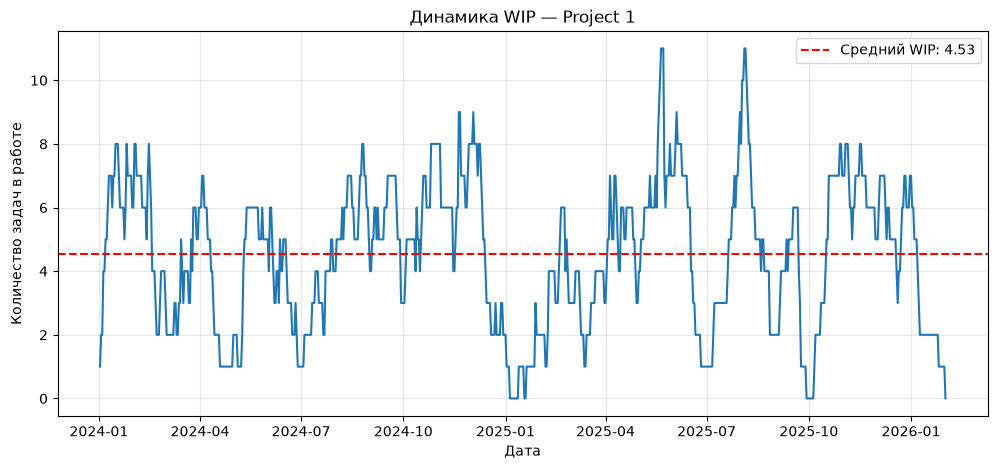

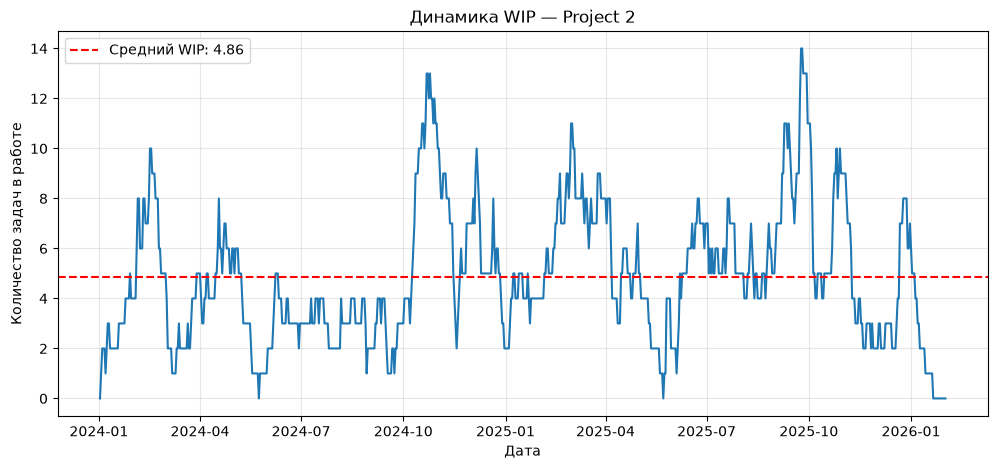

In [170]:
for project_id, group in daily_wip.groupby("project_id"):
    plt.figure(figsize=(12, 5))

    plt.plot(group["date"], group["wip"])

    plt.axhline(
        group["wip"].mean(),
        color="red",
        linestyle="--",
        label=f"Средний WIP: {group['wip'].mean():.2f}"
    )

    plt.title(f"Динамика WIP — Project {project_id}")
    plt.xlabel("Дата")
    plt.ylabel("Количество задач в работе")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [171]:
metrics = pd.DataFrame({
    "Throughput": avg_throughput,
    "Lead Time": avg_lead_time,
    "WIP": avg_wip
})

metrics["WIP по Литтлу"] = (
    metrics["Throughput"] * metrics["Lead Time"]
)

metrics["Погрешность, %"] = (
    abs(metrics["WIP"] - metrics["WIP по Литтлу"])
    / metrics["WIP"] * 100
)

display(metrics.round(2))

,Throughput,Lead Time,WIP,WIP по Литтлу,"Погрешность, %"
project_id,,,,,
1,0.27,16.86,4.53,4.56,0.60
2,0.27,17.83,4.86,4.89,0.59


In [172]:
import numpy as np
import pandas as pd

def calculate_sprint_metrics(sprint_count=1):
    sprint_data = sprints.copy()

    sprint_data["start_date"] = pd.to_datetime(
        sprint_data["start_date"]
    )
    sprint_data["end_date"] = pd.to_datetime(
        sprint_data["end_date"]
    )

    sprint_data = sprint_data.sort_values(
        ["project_id", "start_date"]
    )

    # Формируем периоды из N спринтов
    sprint_data["period_id"] = (
        sprint_data.groupby("project_id").cumcount()
        // sprint_count + 1
    )

    periods = (
        sprint_data.groupby(["project_id", "period_id"])
        .agg(
            start=("start_date", "min"),
            end=("end_date", "max")
        )
        .reset_index()
    )

    results = []

    for p in periods.itertuples(index=False):
        project_id = p.project_id
        dates = pd.date_range(p.start, p.end, freq="D")

        # Throughput за период
        tp = daily_throughput[
            daily_throughput["project_id"] == project_id
        ].set_index("date")["throughput"]

        avg_tp = tp.reindex(dates, fill_value=0).mean()

        # WIP за период
        wip = daily_wip[
            daily_wip["project_id"] == project_id
        ].set_index("date")["wip"]

        avg_wip = wip.reindex(dates, fill_value=0).mean()

        # Lead Time завершённых в периоде задач
        completed = df[
            (df["project_id"] == project_id)
            & df["resolved_at"].dt.normalize().between(
                p.start, p.end
            )
        ]

        avg_lead = completed["lead_time_days"].mean()

        # Закон Литтла
        expected_wip = avg_tp * avg_lead

        error = (
            abs(avg_wip - expected_wip) / avg_wip * 100
            if avg_wip > 0 and pd.notna(expected_wip)
            else np.nan
        )

        results.append({
            "project_id": project_id,
            "period_id": p.period_id,
            "Throughput": avg_tp,
            "Lead Time": avg_lead,
            "WIP": avg_wip,
            "WIP по Литтлу": expected_wip,
            "Погрешность, %": error
        })

    return pd.DataFrame(results)

In [173]:
results_1 = calculate_sprint_metrics(1)
results_4 = calculate_sprint_metrics(4)

def summarize(results):
    return (
        results.groupby("project_id")
        .agg({
            "Throughput": "mean",
            "Lead Time": "mean",
            "WIP": "mean",
            "Погрешность, %": "mean"
        })
        .round(2)
    )

summary_1 = summarize(results_1)
summary_4 = summarize(results_4)

print("Период — 1 спринт")
display(summary_1)

print("Период — 4 спринта")
display(summary_4)

Период — 1 спринт


,Throughput,Lead Time,WIP,"Погрешность, %"
project_id,,,,
1,0.27,16.52,4.60,71.50
2,0.27,17.48,4.99,49.79


Период — 4 спринта


,Throughput,Lead Time,WIP,"Погрешность, %"
project_id,,,,
1,0.27,16.48,4.60,16.41
2,0.27,17.72,4.99,13.10


In [174]:
comparison = pd.DataFrame({
    "1 спринт, %": summary_1["Погрешность, %"],
    "4 спринта, %": summary_4["Погрешность, %"]
})

comparison["Изменение, п.п."] = (
    comparison["4 спринта, %"]
    - comparison["1 спринт, %"]
)

display(comparison.round(2))

,"1 спринт, %","4 спринта, %","Изменение, п.п."
project_id,,,
1,71.50,16.41,-55.09
2,49.79,13.10,-36.69


In [175]:
# Эмпирическое распределение Throughput
empirical_throughput = (
    daily_throughput
    .groupby("project_id")["throughput"]
    .value_counts(normalize=True)
    .rename("probability")
    .reset_index()
    .sort_values(["project_id", "throughput"])
)

display(empirical_throughput)

,project_id,throughput,probability
0,1,0,0.754593
1,1,1,0.223097
2,1,2,0.020997
3,1,4,0.001312
4,2,0,0.761155
5,2,1,0.207349
6,2,2,0.027559
7,2,3,0.003937


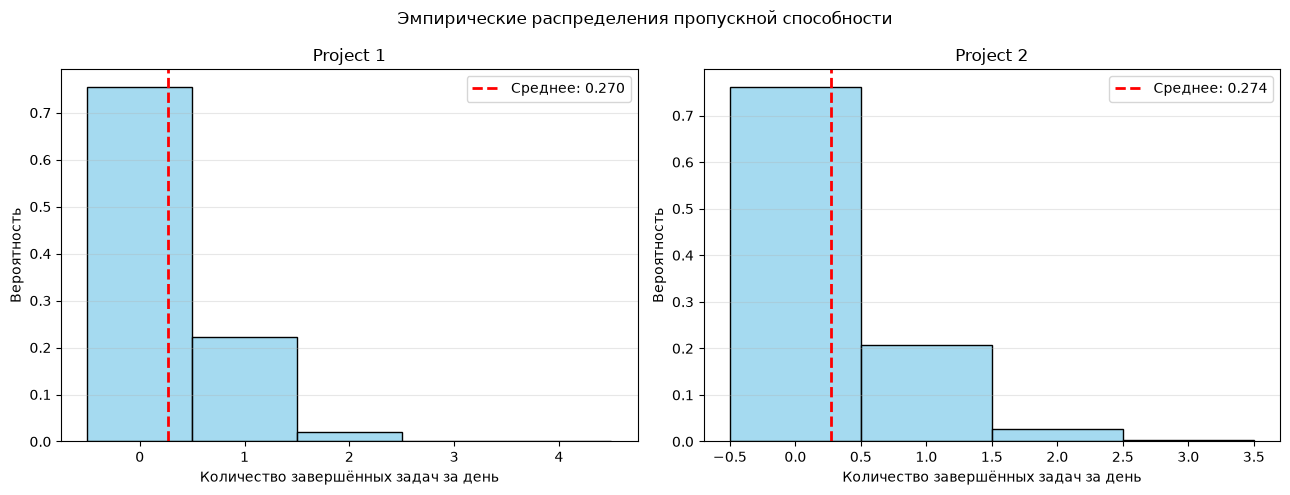

In [176]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (project_id, group) in zip(
    axes,
    daily_throughput.groupby("project_id")
):
    sns.histplot(
        data=group,
        x="throughput",
        discrete=True,
        stat="probability",
        color="skyblue",
        edgecolor="black",
        ax=ax
    )

    mean_tp = group["throughput"].mean()

    ax.axvline(
        mean_tp,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Среднее: {mean_tp:.3f}"
    )

    ax.set_title(f"Project {project_id}")
    ax.set_xlabel("Количество завершённых задач за день")
    ax.set_ylabel("Вероятность")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Эмпирические распределения пропускной способности"
)

plt.tight_layout()
plt.show()


In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

NUM_SIMULATIONS = 10_000
TASKS_TO_COMPLETE = 50

rng = np.random.default_rng(42)

In [178]:

simulation_results = {}

for project_id, group in daily_throughput.groupby("project_id"):

    historical_throughput = group["throughput"].to_numpy()

    if historical_throughput.mean() <= 0:
        raise ValueError(
            f"В проекте {project_id} отсутствуют завершения"
        )

    completion_days = []

    for _ in range(NUM_SIMULATIONS):
        completed_tasks = 0
        days = 0

        while completed_tasks < TASKS_TO_COMPLETE:

            # Bootstrap: случайное значение Throughput
            daily_tp = rng.choice(historical_throughput)

            completed_tasks += daily_tp
            days += 1

        completion_days.append(days)

    simulation_results[project_id] = np.array(completion_days)

    print(
        f"Проект {project_id}: "
        f"{len(completion_days)} симуляций"
    )


Проект 1: 10000 симуляций
Проект 2: 10000 симуляций


C:\Users\Admin\AppData\Local\Temp\ipykernel_10932\1744980807.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mc_results.round(2))


,Проект,Средний срок,"P50, дней","P85, дней","P95, дней",Дата P50,Дата P85,Дата P95
0,1,185.44,184,212,229,2026-08-04,2026-09-01,2026-09-18
1,2,182.76,182,209,228,2026-08-02,2026-08-29,2026-09-17


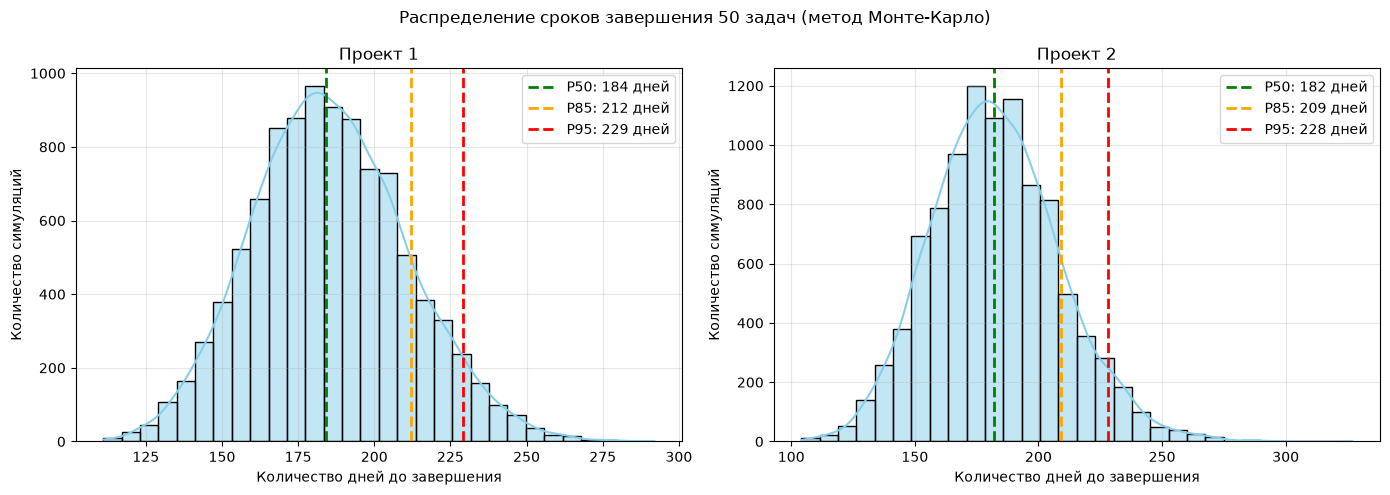

In [179]:

forecast_start = (
    pd.to_datetime(daily_throughput["date"]).max().normalize()
    + pd.Timedelta(days=1)
)

results = []

for project_id, days in simulation_results.items():

    p50, p85, p95 = [
        int(np.ceil(np.percentile(days, p)))
        for p in [50, 85, 95]
    ]

    results.append({
        "Проект": project_id,
        "Средний срок": days.mean(),
        "P50, дней": p50,
        "P85, дней": p85,
        "P95, дней": p95,
        "Дата P50": forecast_start + pd.Timedelta(days=p50 - 1),
        "Дата P85": forecast_start + pd.Timedelta(days=p85 - 1),
        "Дата P95": forecast_start + pd.Timedelta(days=p95 - 1)
    })

mc_results = pd.DataFrame(results)

display(mc_results.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (project_id, days) in zip(
    axes,
    simulation_results.items()
):
    sns.histplot(
        days,
        bins=30,
        kde=True,
        color="skyblue",
        edgecolor="black",
        ax=ax
    )

    for p, color in zip(
        [50, 85, 95],
        ["green", "orange", "red"]
    ):
        value = int(np.ceil(np.percentile(days, p)))

        ax.axvline(
            value,
            color=color,
            linestyle="--",
            linewidth=2,
            label=f"P{p}: {value} дней"
        )

    ax.set_title(f"Проект {project_id}")
    ax.set_xlabel("Количество дней до завершения")
    ax.set_ylabel("Количество симуляций")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Распределение сроков завершения 50 задач "
    "(метод Монте-Карло)"
)

plt.tight_layout()
plt.show()
